# 📚 Master Machine Learning Models Syntactic Guide

This notebook provides the **exact syntax**, parameter configurations, and working execution for all Supervised and Unsupervised Learning models:

- **1. Pipeline & General Syntax** (`make_pipeline`, `fit`, `predict`, `predict_proba`, `score`)
- **2. Linear & Logistic Models** (`LinearRegression`, `Ridge`, `Lasso`, `LogisticRegression`)
- **3. Decision Trees** (`DecisionTreeClassifier`, `DecisionTreeRegressor`)
- **4. Naive Bayes, KNN & Support Vector Machines** (`GaussianNB`, `MultinomialNB`, `BernoulliNB`, `KNeighborsClassifier`, `SVC`, `SVR`)
- **5. Bagging & Random Forest** (`BaggingClassifier`, `RandomForestClassifier`, `BaggingRegressor`, `RandomForestRegressor`)
- **6. Boosting** (`AdaBoostClassifier`, `GradientBoostingClassifier`, `XGBClassifier`, `AdaBoostRegressor`, `GradientBoostingRegressor`, `XGBRegressor`)
- **7. Stacking Ensembles** (`StackingClassifier`, `StackingRegressor`)
- **8. Unsupervised Models** (`KMeans` with WCSS/Centroids, `PCA` with Explained Variance)
- **9. Exam Customization Checklist** (The exact parameters & lines to change for any exam dataset)


## 0. Setup & Data Preparation\nPrepare standard Classification (*Breast Cancer*) and Regression (*Diabetes*) datasets.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

# 1. Classification Data (Breast Cancer)
cancer = load_breast_cancer(as_frame=True)
X_c, y_c = cancer.data, cancer.target
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)

scaler_c = StandardScaler()
X_tr_c_scaled = scaler_c.fit_transform(X_tr_c)
X_te_c_scaled = scaler_c.transform(X_te_c)

# 2. Regression Data (Diabetes)
diabetes = load_diabetes(as_frame=True)
X_r, y_r = diabetes.data, diabetes.target
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_r, y_r, test_size=0.2, random_state=42)

scaler_r = StandardScaler()
X_tr_r_scaled = scaler_r.fit_transform(X_tr_r)
X_te_r_scaled = scaler_r.transform(X_te_r)

print(f"✓ Classification Set: {X_tr_c.shape[0]} train, {X_te_c.shape[0]} test samples")
print(f"✓ Regression Set:     {X_tr_r.shape[0]} train, {X_te_r.shape[0]} test samples")

✓ Classification Set: 455 train, 114 test samples
✓ Regression Set:     353 train, 89 test samples


---
## 1. Pipeline & General Syntax

### Pipeline
```python
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(<step1>, <step2>, ...)
```

### General Pattern
```python
model.fit(<X_train>, <y_train>)
y_pred = model.predict(<X_test>)
y_proba = model.predict_proba(<X_test>)[:, <class_index>]
score = model.score(<X_test>, <y_test>)
```


In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# 1. Pipeline: Combines Preprocessing + Model into a single atomic object
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))

# 2. General Methods
pipe.fit(X_tr_c, y_tr_c)                          # model.fit(<X_train>, <y_train>)
y_pred = pipe.predict(X_te_c)                     # y_pred = model.predict(<X_test>)
y_proba = pipe.predict_proba(X_te_c)[:, 1]        # y_proba = model.predict_proba(<X_test>)[:, <class_index>]
score = pipe.score(X_te_c, y_te_c)                # score = model.score(<X_test>, <y_test>)

print(f"Pipeline Test Accuracy: {score * 100:.2f}%")
print(f"Sample Predictions (first 5): {y_pred[:5]}")
print(f"Sample Probabilities (first 5): {y_proba[:5].round(4)}")

Pipeline Test Accuracy: 98.25%
Sample Predictions (first 5): [0 1 0 1 0]
Sample Probabilities (first 5): [0.     1.     0.0064 0.5335 0.    ]


---
## 2. Linear & Logistic Models

```python
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, LogisticRegression
)

LinearRegression()
Ridge(alpha=<alpha>)
Lasso(alpha=<alpha>)
LogisticRegression(
    penalty=<"l1"/"l2"/"elasticnet"/"none">,
    C=<float>,
    solver=<"liblinear"/"saga"/"lbfgs">,
    l1_ratio=<float_or_None>,
    random_state=<int>
)
```


In [3]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression

print("--- 2.1 Regression Models (Linear, Ridge, Lasso) ---")
# 1. Ordinary Least Squares
lr = LinearRegression()
lr.fit(X_tr_r_scaled, y_tr_r)
print(f"LinearRegression R² Score: {lr.score(X_te_r_scaled, y_te_r):.4f}")

# 2. Ridge (L2 Regularization)
ridge = Ridge(alpha=1.0)
ridge.fit(X_tr_r_scaled, y_tr_r)
print(f"Ridge (alpha=1.0) R² Score: {ridge.score(X_te_r_scaled, y_te_r):.4f}")

# 3. Lasso (L1 Regularization - Feature Sparsity)
lasso = Lasso(alpha=0.1)
lasso.fit(X_tr_r_scaled, y_tr_r)
print(f"Lasso (alpha=0.1) R² Score: {lasso.score(X_te_r_scaled, y_te_r):.4f}")

print("\n--- 2.2 Logistic Regression with Regularization Solvers ---")
# L2 Penalty (Default, lbfgs solver)
log_l2 = LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", random_state=42)
log_l2.fit(X_tr_c_scaled, y_tr_c)
print(f"LogisticRegression (penalty='l2', solver='lbfgs') Accuracy: {log_l2.score(X_te_c_scaled, y_te_c)*100:.2f}%")

# L1 Penalty (liblinear or saga solver)
log_l1 = LogisticRegression(penalty="l1", C=0.5, solver="liblinear", random_state=42)
log_l1.fit(X_tr_c_scaled, y_tr_c)
print(f"LogisticRegression (penalty='l1', solver='liblinear') Accuracy: {log_l1.score(X_te_c_scaled, y_te_c)*100:.2f}%")

# ElasticNet Penalty (saga solver, l1_ratio: 0=L2, 1=L1)
log_enet = LogisticRegression(penalty="elasticnet", C=0.5, solver="saga", l1_ratio=0.5, random_state=42)
log_enet.fit(X_tr_c_scaled, y_tr_c)
print(f"LogisticRegression (penalty='elasticnet', solver='saga') Accuracy: {log_enet.score(X_te_c_scaled, y_te_c)*100:.2f}%")

--- 2.1 Regression Models (Linear, Ridge, Lasso) ---
LinearRegression R² Score: 0.4526
Ridge (alpha=1.0) R² Score: 0.4541
Lasso (alpha=0.1) R² Score: 0.4555

--- 2.2 Logistic Regression with Regularization Solvers ---
LogisticRegression (penalty='l2', solver='lbfgs') Accuracy: 98.25%
LogisticRegression (penalty='l1', solver='liblinear') Accuracy: 97.37%
LogisticRegression (penalty='elasticnet', solver='saga') Accuracy: 97.37%


C:\Users\priya\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


---
## 3. Decision Tree (Classifier & Regressor)

```python
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

DecisionTreeClassifier(
    criterion=<"gini"/"entropy">,
    max_depth=<int_or_None>,
    min_samples_split=<int>,
    min_samples_leaf=<int>,
    random_state=<int>
)

DecisionTreeRegressor(
    criterion=<"squared_error"/"friedman_mse"/"absolute_error">,
    max_depth=<int_or_None>,
    min_samples_split=<int>,
    random_state=<int>
)
```


In [4]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# 1. Decision Tree Classifier
dt_clf = DecisionTreeClassifier(
    criterion="gini",         # or "entropy"
    max_depth=4,              # Controls tree depth to avoid overfitting
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)
dt_clf.fit(X_tr_c, y_tr_c)
print(f"DecisionTreeClassifier (max_depth=4) Accuracy: {dt_clf.score(X_te_c, y_te_c)*100:.2f}%")

# 2. Decision Tree Regressor
dt_reg = DecisionTreeRegressor(
    criterion="squared_error", # or "friedman_mse", "absolute_error"
    max_depth=4,
    min_samples_split=2,
    random_state=42
)
dt_reg.fit(X_tr_r, y_tr_r)
print(f"DecisionTreeRegressor (max_depth=4) R² Score:    {dt_reg.score(X_te_r, y_te_r):.4f}")

DecisionTreeClassifier (max_depth=4) Accuracy: 93.86%
DecisionTreeRegressor (max_depth=4) R² Score:    0.3264


---
## 4. Naive Bayes, KNN, SVM

```python
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, SVR

GaussianNB()
MultinomialNB()
BernoulliNB()

KNeighborsClassifier(
    n_neighbors=<int>,
    algorithm=<"auto"/"ball_tree"/"kd_tree">
)

SVC(
    kernel=<"linear"/"poly"/"rbf"/"sigmoid">,
    C=<float>,
    degree=<int>,
    gamma=<"scale"/"auto">,
    probability=<True/False>,
    random_state=<int>
)

SVR(
    kernel=<"linear"/"poly"/"rbf"/"sigmoid">,
    C=<float>,
    degree=<int>,          # for 'poly' kernel
    gamma=<"scale"/"auto">, # kernel coefficient
    epsilon=<float>        # tolerance margin
)
```


In [5]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, SVR

print("--- 4.1 Naive Bayes Models ---")
# GaussianNB: continuous bell-curve features
gnb = GaussianNB()
gnb.fit(X_tr_c, y_tr_c)
print(f"GaussianNB Accuracy:   {gnb.score(X_te_c, y_te_c)*100:.2f}%")

# MultinomialNB: discrete/count/non-negative data (MinMaxScaler used)
scaler_minmax = MinMaxScaler()
X_tr_c_pos = scaler_minmax.fit_transform(X_tr_c)
X_te_c_pos = scaler_minmax.transform(X_te_c)
mnb = MultinomialNB().fit(X_tr_c_pos, y_tr_c)
print(f"MultinomialNB Accuracy: {mnb.score(X_te_c_pos, y_te_c)*100:.2f}%")

# BernoulliNB: binary/boolean indicators
bnb = BernoulliNB().fit(X_tr_c_scaled > 0, y_tr_c)
print(f"BernoulliNB Accuracy:   {bnb.score(X_te_c_scaled > 0, y_te_c)*100:.2f}%")

print("\n--- 4.2 K-Nearest Neighbors ---")
knn = KNeighborsClassifier(n_neighbors=5, algorithm="auto")
knn.fit(X_tr_c_scaled, y_tr_c)
print(f"KNeighborsClassifier (n_neighbors=5, algorithm='auto') Accuracy: {knn.score(X_te_c_scaled, y_te_c)*100:.2f}%")

print("\n--- 4.3 Support Vector Machines (SVC & SVR) ---")
# SVC (Classification)
svc_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=42)
svc_rbf.fit(X_tr_c_scaled, y_tr_c)
print(f"SVC (kernel='rbf', C=1.0) Accuracy: {svc_rbf.score(X_te_c_scaled, y_te_c)*100:.2f}%")

svc_lin = SVC(kernel="linear", C=1.0, probability=True, random_state=42)
svc_lin.fit(X_tr_c_scaled, y_tr_c)
print(f"SVC (kernel='linear', C=1.0) Accuracy: {svc_lin.score(X_te_c_scaled, y_te_c)*100:.2f}%")

# SVR (Regression)
svr = SVR(kernel="rbf", C=1.0, gamma="scale", epsilon=0.1)
svr.fit(X_tr_r_scaled, y_tr_r)
print(f"SVR (kernel='rbf', C=1.0, epsilon=0.1) R² Score: {svr.score(X_te_r_scaled, y_te_r):.4f}")

--- 4.1 Naive Bayes Models ---
GaussianNB Accuracy:   93.86%
MultinomialNB Accuracy: 85.96%
BernoulliNB Accuracy:   92.98%

--- 4.2 K-Nearest Neighbors ---


KNeighborsClassifier (n_neighbors=5, algorithm='auto') Accuracy: 95.61%

--- 4.3 Support Vector Machines (SVC & SVR) ---
SVC (kernel='rbf', C=1.0) Accuracy: 98.25%
SVC (kernel='linear', C=1.0) Accuracy: 97.37%
SVR (kernel='rbf', C=1.0, epsilon=0.1) R² Score: 0.1822


---
## 5. Bagging & Random Forest

```python
from sklearn.ensemble import (
    BaggingClassifier, BaggingRegressor,
    RandomForestClassifier, RandomForestRegressor
)

BaggingClassifier(
    estimator=<est>,
    n_estimators=<int>,
    max_samples=<float>,
    max_features=<float>,
    random_state=<int>
)

RandomForestClassifier(
    n_estimators=<int>,
    criterion=<"gini"/"entropy">,
    max_depth=<int_or_None>,
    min_samples_split=<int>,
    max_features=<"sqrt"/"log2"/<float>>,
    random_state=<int>
)

BaggingRegressor(...)
RandomForestRegressor(...)
```


In [6]:
from sklearn.ensemble import (
    BaggingClassifier, BaggingRegressor,
    RandomForestClassifier, RandomForestRegressor
)

print("--- 5.1 Bagging & Random Forest Classification ---")
# 1. Bagging Classifier
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=3),
    n_estimators=15,
    max_samples=0.8,
    max_features=0.8,
    random_state=42
)
bag_clf.fit(X_tr_c, y_tr_c)
print(f"BaggingClassifier Accuracy:      {bag_clf.score(X_te_c, y_te_c)*100:.2f}%")

# 2. Random Forest Classifier
rf_clf = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    max_features="sqrt",
    random_state=42
)
rf_clf.fit(X_tr_c, y_tr_c)
print(f"RandomForestClassifier Accuracy: {rf_clf.score(X_te_c, y_te_c)*100:.2f}%")

print("\n--- 5.2 Bagging & Random Forest Regression ---")
# 3. Bagging Regressor
bag_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=15,
    max_samples=0.8,
    random_state=42
)
bag_reg.fit(X_tr_r, y_tr_r)
print(f"BaggingRegressor R² Score:      {bag_reg.score(X_te_r, y_te_r):.4f}")

# 4. Random Forest Regressor
rf_reg = RandomForestRegressor(
    n_estimators=100,
    criterion="squared_error",
    max_depth=5,
    min_samples_split=2,
    max_features="sqrt",
    random_state=42
)
rf_reg.fit(X_tr_r, y_tr_r)
print(f"RandomForestRegressor R² Score: {rf_reg.score(X_te_r, y_te_r):.4f}")

--- 5.1 Bagging & Random Forest Classification ---
BaggingClassifier Accuracy:      94.74%


RandomForestClassifier Accuracy: 95.61%

--- 5.2 Bagging & Random Forest Regression ---
BaggingRegressor R² Score:      0.4548


RandomForestRegressor R² Score: 0.4674


---
## 6. Boosting (AdaBoost, Gradient Boosting & XGBoost)

```python
from sklearn.ensemble import (
    AdaBoostClassifier, AdaBoostRegressor,
    GradientBoostingClassifier, GradientBoostingRegressor
)
from xgboost import XGBClassifier, XGBRegressor

AdaBoostClassifier(
    estimator=DecisionTreeClassifier(...),
    n_estimators=<int>,
    learning_rate=<float>,
    random_state=<int>
)

GradientBoostingClassifier(
    n_estimators=<int>,
    learning_rate=<float>,
    max_depth=<int>,
    min_samples_split=<int>,
    min_samples_leaf=<int>,
    subsample=<float>,
    max_features=<"sqrt"/"log2">,
    random_state=<int>
)

XGBClassifier(
    eval_metric=<"logloss">,
    n_estimators=<int>,
    max_depth=<int>,
    learning_rate=<float>,
    subsample=<float>,
    random_state=<int>
)
```


In [7]:
from sklearn.ensemble import (
    AdaBoostClassifier, AdaBoostRegressor,
    GradientBoostingClassifier, GradientBoostingRegressor
)
from xgboost import XGBClassifier, XGBRegressor

print("--- 6.1 Boosting Classifiers ---")
# 1. AdaBoost Classifier
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)
ada_clf.fit(X_tr_c, y_tr_c)
print(f"AdaBoostClassifier Accuracy:         {ada_clf.score(X_te_c, y_te_c)*100:.2f}%")

# 2. Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    subsample=1.0,
    max_features="sqrt",
    random_state=42
)
gb_clf.fit(X_tr_c, y_tr_c)
print(f"GradientBoostingClassifier Accuracy: {gb_clf.score(X_te_c, y_te_c)*100:.2f}%")

# 3. XGBoost Classifier
xgb_clf = XGBClassifier(
    eval_metric="logloss",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42
)
xgb_clf.fit(X_tr_c, y_tr_c)
print(f"XGBClassifier Accuracy:              {xgb_clf.score(X_te_c, y_te_c)*100:.2f}%")

print("\n--- 6.2 Boosting Regressors ---")
ada_reg = AdaBoostRegressor(n_estimators=50, learning_rate=1.0, random_state=42)
ada_reg.fit(X_tr_r, y_tr_r)
print(f"AdaBoostRegressor R²:                {ada_reg.score(X_te_r, y_te_r):.4f}")

gb_reg = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_reg.fit(X_tr_r, y_tr_r)
print(f"GradientBoostingRegressor R²:        {gb_reg.score(X_te_r, y_te_r):.4f}")

xgb_reg = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8, random_state=42)
xgb_reg.fit(X_tr_r, y_tr_r)
print(f"XGBRegressor R²:                     {xgb_reg.score(X_te_r, y_te_r):.4f}")

--- 6.1 Boosting Classifiers ---


AdaBoostClassifier Accuracy:         95.61%


GradientBoostingClassifier Accuracy: 95.61%


XGBClassifier Accuracy:              95.61%

--- 6.2 Boosting Regressors ---


AdaBoostRegressor R²:                0.4301


GradientBoostingRegressor R²:        0.4529


XGBRegressor R²:                     0.4352


---
## 7. Stacking Ensembles

Combines predictions from multiple diverse base estimators using a meta-learner:

```python
from sklearn.ensemble import StackingClassifier, StackingRegressor

StackingClassifier(
    estimators=[("<name>", <estimator>), ...],
    final_estimator=<estimator>,
    cv=<int>,
    n_jobs=<int>
)

StackingRegressor(
    estimators=[("<name>", <estimator>), ...],
    final_estimator=<estimator>,
    cv=<int>,
    n_jobs=<int>
)
```


In [8]:
from sklearn.ensemble import StackingClassifier, StackingRegressor
from sklearn.linear_model import LogisticRegression, Ridge

print("--- 7.1 Stacking Classifier ---")
base_classifiers = [
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=50, random_state=42)),
    ("svc", SVC(probability=True, random_state=42))
]

stack_clf = StackingClassifier(
    estimators=base_classifiers,
    final_estimator=LogisticRegression(),
    cv=5
)
stack_clf.fit(X_tr_c_scaled, y_tr_c)
print(f"StackingClassifier Accuracy: {stack_clf.score(X_te_c_scaled, y_te_c)*100:.2f}%")

print("\n--- 7.2 Stacking Regressor ---")
base_regressors = [
    ("ridge", Ridge(alpha=1.0)),
    ("rf", RandomForestRegressor(n_estimators=50, random_state=42)),
    ("svr", SVR(kernel='rbf', C=1.0))
]

stack_reg = StackingRegressor(
    estimators=base_regressors,
    final_estimator=LinearRegression(),
    cv=5
)
stack_reg.fit(X_tr_r_scaled, y_tr_r)
print(f"StackingRegressor R² Score:  {stack_reg.score(X_te_r_scaled, y_te_r):.4f}")

--- 7.1 Stacking Classifier ---


StackingClassifier Accuracy: 97.37%

--- 7.2 Stacking Regressor ---


StackingRegressor R² Score:  0.4663


---
## 8. Unsupervised Learning Models (Syntactic)

### 8.1 K-Means Clustering
```python
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=<int>,
    random_state=<int>
)
kmeans.fit(<X>)
wcss = kmeans.inertia_
labels = kmeans.labels_
centers = kmeans.cluster_centers_
```

### 8.2 Principal Component Analysis (PCA)
```python
from sklearn.decomposition import PCA

pca = PCA(n_components=<int>)
pca.fit(<X>)
X_pca = pca.transform(<X>)
evr = pca.explained_variance_ratio_
```


=== K-Means Clustering Results ===


Number of clusters: 3
WCSS / Inertia:     191.02
Labels shape:       (150,)
Cluster Centers shape: (3, 4)
Sample Cluster Labels: [1 2 2 2 1 1 1 1 2 2]

=== PCA Results ===
Explained Variance Ratio per component: [0.7296 0.2285]
Total Variance Explained: 95.81%
Transformed X_pca shape:  (150, 2)


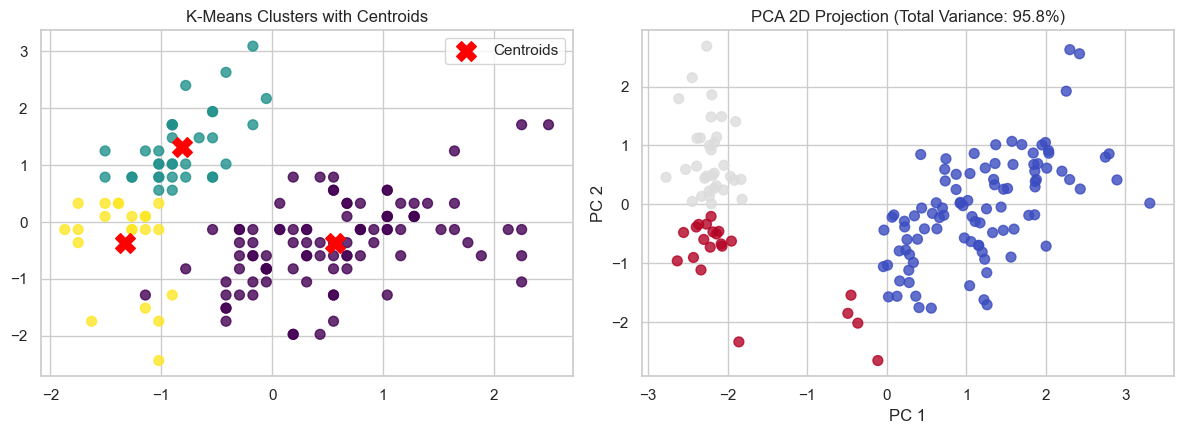

In [9]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris

# --- 8.1 K-Means Clustering (Iris Data without Labels) ---
iris = load_iris()
X_iris_raw = iris.data
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris_raw)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init='auto'
)
kmeans.fit(X_iris_scaled)

wcss = kmeans.inertia_             # Within-Cluster Sum of Squares (Inertia)
labels = kmeans.labels_            # Predicted cluster assignments (0, 1, 2)
centers = kmeans.cluster_centers_  # Centroid coordinate matrix

print("=== K-Means Clustering Results ===")
print(f"Number of clusters: {kmeans.n_clusters}")
print(f"WCSS / Inertia:     {wcss:.2f}")
print(f"Labels shape:       {labels.shape}")
print(f"Cluster Centers shape: {centers.shape}")
print(f"Sample Cluster Labels: {labels[:10]}")

# --- 8.2 PCA Dimensionality Reduction ---
pca = PCA(n_components=2)
pca.fit(X_iris_scaled)
X_pca = pca.transform(X_iris_scaled)
evr = pca.explained_variance_ratio_

print("\n=== PCA Results ===")
print(f"Explained Variance Ratio per component: {evr.round(4)}")
print(f"Total Variance Explained: {evr.sum()*100:.2f}%")
print(f"Transformed X_pca shape:  {X_pca.shape}")

# Plotting Clusters & PCA 2D
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=labels, cmap='viridis', s=50, alpha=0.8)
axes[0].scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
axes[0].set_title("K-Means Clusters with Centroids")
axes[0].legend()

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='coolwarm', s=50, alpha=0.8)
axes[1].set_title(f"PCA 2D Projection (Total Variance: {evr.sum()*100:.1f}%)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")

plt.tight_layout()
plt.show()

---
## 9. 🎯 Exam Customization Checklist: "What to change for any dataset?"

| Exam Question Requirement | What to Change in Code | Example |
|---|---|---|
| **1. Custom CSV File** | `df = pd.read_csv("filename.csv")` | `df = pd.read_csv("exam_dataset.csv")` |
| **2. Target Column** | `y = df["target_name"]`, `X = df.drop(columns=["target_name"])` | `X = df.drop(columns=['Price'])`, `y = df['Price']` |
| **3. Linear Regression with Regularization** | Choose between `Ridge(alpha=...)` (L2) or `Lasso(alpha=...)` (L1) | `model = Ridge(alpha=0.5)` |
| **4. Logistic Regression with L1 Penalty** | `penalty="l1"`, `solver="liblinear"` | `LogisticRegression(penalty="l1", solver="liblinear")` |
| **5. Decision Tree Depth Limit** | `max_depth=<int>` (prevents overfitting) | `DecisionTreeClassifier(max_depth=3)` |
| **6. Number of Neighbors (KNN)** | `n_neighbors=<int>` | `KNeighborsClassifier(n_neighbors=7)` |
| **7. SVM Kernel** | `kernel="linear"`, `"rbf"`, or `"poly"` | `SVC(kernel="linear", C=1.0)` |
| **8. Random Forest Tree Count** | `n_estimators=<int>` | `RandomForestClassifier(n_estimators=200)` |
| **9. Boosting Algorithm** | Choose `AdaBoostClassifier`, `GradientBoostingClassifier`, or `XGBClassifier` | `GradientBoostingClassifier(learning_rate=0.05)` |
| **10. Optimal Clusters in K-Means** | `n_clusters=<int>` (or loop with `kmeans.inertia_` for Elbow plot) | `KMeans(n_clusters=4)` |
| **11. Target Variance in PCA** | `n_components=0.95` (to keep 95% variance) | `PCA(n_components=0.95)` |
